# Backbone bake-off on EuroSAT: ResNet-50 vs ViT-S/16 vs ConvNeXt-T

**Question:** under one fixed training recipe, which backbone + init gives the best accuracy / speed trade-off on Sentinel-2 scene classification, and how does that change with label scarcity?

## Grid — `configs/grid.yaml`
| axis | values |
|---|---|
| backbone | `resnet50` (25.6M), `vit_small_patch16_224` (22.1M), `convnext_tiny` (28.6M) |
| init | **imagenet_rgb**: timm ImageNet weights, input = RGB (B04,B03,B02), `in_chans=3` — all backbones<br>**s2_ssl**: torchgeo SSL4EO-S12 MoCo weights, input = all 13 L1C bands, `in_chans=13` — ResNet-50, ViT-S<br>**imagenet_13ch**: ImageNet weights, stem stretched to 13ch (see *Models* section) — ConvNeXt-T (its 13-band row; addable to others to separate "more bands" from "in-domain pretraining") |
| mode | **lp** = linear probe (frozen backbone, cached features) · **ft** = full fine-tune |
| label fraction | 1% (≈162 imgs, ~16/class), 10% (1 620), 100% (16 200) of the train split; stratified, resampled per seed |
| seed | 0, 1, 2 (seed controls subset, head init, data order, aug) |

Weights:
- `resnet50.a1_in1k` · `vit_small_patch16_224.augreg_in21k_ft_in1k` · `convnext_tiny.fb_in22k`
- `ResNet50_Weights.SENTINEL2_ALL_MOCO` · `ViTSmall16_Weights.SENTINEL2_ALL_MOCO` (DINO also available, switch in config)
- **no S2-SSL ConvNeXt in torchgeo** → ConvNeXt's 13-band row uses `imagenet_13ch` instead.

Runs: FT = 6 (backbone,init) × 3 fractions × 3 seeds = **54**; LP = same 54 but cheap (features extracted once per backbone/init).

## Data — EuroSAT (torchgeo, 13-band L1C, 64×64, 10 classes)
- Official torchgeo split: train 16 200 / val 5 400 / test 5 400. Test only for final numbers.
- Whole dataset cached once as `int16` numpy (≈2.9 GB RAM). Batches indexed on CPU, preprocessing on GPU → no dataloader bottleneck, identical pipeline for every model.
- **Band order gotcha:** torchgeo EuroSAT stores `B8A` *last*; SSL4EO weights expect `…B08, B8A, B09…`. Cache is reordered to SSL4EO order.
- Upsampled 64→224 (bilinear) for all models: matches pretraining res, ViT pos-embeds, and makes throughput comparable. (torchgeo's own transform is resize 256 + center-crop 224; plain resize keeps the full tile.)

Normalisation (per init, matches how each was pretrained):
- `s2_ssl`: DN / 10 000 (exactly torchgeo's SSL4EO transform).
- `imagenet_rgb`: clip(DN / 3000, 0, 1) → model's own `pretrained_cfg` mean/std (**note** ViT augreg uses 0.5/0.5, not ImageNet stats).
- `imagenet_13ch`: per-band z-score with train stats (needed so the stretched stem's 3/13 scaling keeps activations at ImageNet scale).

## Recipe (identical for all backbones) — `configs/default.yaml`
**Full FT:** AdamW, lr 2e-4, wd 0.05 (no wd on norm/bias), 5% linear warmup → cosine, label smoothing 0.1, grad-clip 1.0, bs 64, bf16 autocast, channels_last. Aug = random D4 (h-flip, v-flip, transpose = all 8 dihedral variants; orientation-invariant for nadir EO). Epochs per fraction (same for every backbone): 1% → 200, 10% → 50, 100% → 15 (≈400 / 1 250 / 3 800 steps; same epochs across fractions would give 1% only a few dozen steps). Report **last-epoch** test top-1 (no early-stopping on test).

**Linear probe:** frozen backbone in eval, pooled pre-logit features (no aug), standardised; linear head trained with AdamW (100 epochs, cosine), wd chosen from a small grid on **val** → test top-1. Standard SSL-eval protocol.

## Efficiency metrics — `python -m bakeoff.bench`
Synthetic batch, bs 64, 224², bf16 autocast, channels_last, warmup then timed with `cuda.synchronize`. Reports:
- inference img/s + peak memory (`max_memory_allocated`), and
- train-step img/s + peak memory (fwd+bwd+AdamW) — relevant for FT vs LP cost.

Measured for `in_chans=3` and `13` (only stem changes; difference should be tiny). Weights irrelevant to speed → random init.

## Code layout
This notebook only **launches** and **analyses**; all training code is the `bakeoff` package (tested, `pytest`):
| module | role | CLI |
|---|---|---|
| `data` | EuroSAT int16 cache, band order, stratified subsets, GPU prep/aug | |
| `models` | `build(backbone, init)` for the 3 inits (see *Models* below) | |
| `config` | `RunConfig` from YAML + `--set k=v`; `config_hash` = run id (recipe only, no paths) | |
| `train` | one run: FT (Lightning) or LP (feature cache + linear head) → row in `results.csv` | `python -m bakeoff.train --config configs/default.yaml --set mode=lp` |
| `grid` | grid YAML → one subprocess per run; skips finished hashes; failures → `failures.csv` | `python -m bakeoff.grid configs/grid.yaml` |
| `tune` | sweep results → best `top1_val` per (backbone, init) → tuned grid (`rules`) | `python -m bakeoff.tune configs/sweep.yaml configs/grid.yaml` |
| `bench` | throughput / peak mem per (backbone, in_chans) → `bench.csv` | `python -m bakeoff.bench --out bench.csv` |
| `analysis` | varied hparams from row configs, seed-mean summary, paired deltas, Pareto | |

Each `results.csv` row stores its full recipe (`config` JSON). Analysis groups by any recipe key that varies within a (mode, fraction) → sweeps show up as extra table columns / Pareto rows with no notebook edits. To pool recipes instead (e.g. lr tuned per backbone), pass `split_by=[...]` explicitly.

## Deliverables
1. `results.csv` (one row per run, resumable by `config_hash`) + `bench.csv` + `logs/<hash>.log`, `failures.csv`
2. Summary table: top-1 mean ± std over seeds, per (backbone, init, mode, fraction, varied hparams), joined with img/s & peak mem
3. FT−LP gap and seed-paired deltas (init vs init, hparam value vs value)
4. Pareto plot: accuracy vs inference throughput; cols = label fraction, rows = varied-hparam combo, frontier over FT points

## Caveats
- **Pretraining mismatch across ImageNet inits:** not same data/recipe → arch effect confounded with pretraining.
  | backbone | pretrain data | labels | recipe |
  |---|---|---|---|
  | ResNet-50 `a1_in1k` | IN-1k (1.3M) | supervised | RSB A1, 600 ep |
  | ViT-S `augreg_in21k_ft_in1k` | IN-21k → IN-1k ft | supervised | AugReg |
  | ConvNeXt-T `fb_in22k` | IN-22k (14M) | supervised | ConvNeXt, 90 ep |
  | ResNet-50 / ViT-S `s2_ssl` | SSL4EO-S12 (~1M S2 patches, 13 bands) | self-sup (MoCo) | SSL4EO |

  ViT-S/ConvNeXt-T see ~10× more pretraining data than ResNet-50 → part of any ResNet gap may be data, not arch. Kept as-is: these are the standard/recommended checkpoints. Parity alternative: all IN-1k (`convnext_tiny.fb_in1k`, `vit_small_patch16_224.augreg_in1k`).
- One shared recipe ≠ each backbone's best recipe (ViTs usually want layer-decay / stronger aug) → *tuned* bake-off below (lr, drop-path, wd on val); no layer-decay / aug search.
- LP uses the full val split for wd selection even at 1% labels — slightly optimistic, applied equally to all.
- Throughput is hardware-specific; compare only within one run of this notebook.
- `cudnn.benchmark=True` for speed → runs are not bit-exact reproducible; seeds still fix subsets/init.

Set `QUICK = True` first for a smoke test (`configs/quick.yaml`: 1 seed, 10%, 2 FT epochs; separate `quick/` out dir).

In [1]:
import os, sys, site, importlib, importlib.util, subprocess

# deps missing in jupyter pod / Colab (runs are subprocesses of this kernel's python -> same env)
try:
    import timm, torchgeo, lightning, yaml, matplotlib, tabulate
except ModuleNotFoundError:
    %pip install --quiet "timm>=1.0" "torchgeo>=0.7" "lightning>=2.4" pyyaml matplotlib tabulate
    site.addsitedir(site.getusersitepackages())  # k8s pod: user site may not exist at kernel start
    importlib.invalidate_caches()

# bakeoff package: notebook dir if present, else shallow-clone repo to WORK_DIR (pod/Colab)
REPO, BRANCH = "https://github.com/ignaciomasari/cv_playground", "main"
WORK_DIR = os.environ.get("BAKEOFF_WORK_DIR") or ("/home/jovyan/work" if os.path.isdir("/home/jovyan/work") else "..")  # = bakeoff.config.work_dir()
if importlib.util.find_spec("bakeoff") is None:
    src = os.path.join(WORK_DIR, "cv_playground")
    if not os.path.isdir(src):
        subprocess.run(["git", "clone", "--depth", "1", "-b", BRANCH, REPO, src], check=True)
    else:
        subprocess.run(["git", "-C", src, "pull", "--ff-only"], check=True)
    sys.path.insert(0, os.path.join(src, "backbone_bakeoff"))

import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from bakeoff import analysis as an, setup_logging
from bakeoff.grid import PKG_ROOT, child_env, expand, launch
from bakeoff.results import read_results
from bakeoff.tune import write_tuned
setup_logging()  # launch progress + warnings -> cell output
print("bakeoff:", PKG_ROOT)


Already up to date.
bakeoff: /home/jovyan/work/cv_playground/backbone_bakeoff


## Config

In [2]:
QUICK = False  # True: configs/quick.yaml smoke test (own out dir)
GRID = os.path.join(PKG_ROOT, "configs", "quick.yaml" if QUICK else "grid.yaml")
TIMEOUT_H = 6  # per run; hung run killed -> failures.csv, grid continues

runs = expand(GRID)  # bad keys / values raise here
OUT_DIR = runs[0].cfg.out_dir
RESULTS_CSV, BENCH_CSV = runs[0].cfg.results_csv, os.path.join(OUT_DIR, "bench.csv")
SWEEP = os.path.join(PKG_ROOT, "configs", "sweep_quick.yaml" if QUICK else "sweep.yaml")
TUNED = os.path.join(OUT_DIR, "tuned.yaml")  # written by the tuning cell (results-derived -> not in repo)
print(f"{len(runs)} runs | results -> {os.path.abspath(RESULTS_CSV)}")


108 runs | results -> /home/jovyan/work/saved_models/backbone_bakeoff/results.csv


## Throughput benchmark
bs 64, 224², bf16, channels_last, random weights; `in_chans` 3 and 13. Inference (`inference_mode`) and train step (fwd + bwd + AdamW).

In [3]:
# subprocess -> GPU memory freed after; delete bench.csv to re-measure
if not os.path.isfile(BENCH_CSV):
    os.makedirs(OUT_DIR, exist_ok=True)
    bench_run = subprocess.run([sys.executable, "-m", "bakeoff.bench", "--out", BENCH_CSV],
                               env=child_env(), capture_output=True, text=True)
    print(bench_run.stdout[-3000:], bench_run.stderr[-3000:] if bench_run.returncode else "")
    bench_run.check_returncode()
pd.read_csv(BENCH_CSV).round(1)


,backbone,in_chans,params_M,infer_ips,infer_mem_MB,train_ips,train_mem_MB
0,resnet50,3,23.5,6787.3,478.2,1964.0,3139.7
1,resnet50,13,23.6,6007.4,633.6,1867.1,3321.4
2,vit_s16,3,21.7,8216.0,333.1,2486.2,2529.2
3,vit_s16,13,22.7,7622.8,505.0,2385.5,2723.5
4,convnext_t,3,27.8,3461.5,725.8,1272.9,4291.0
5,convnext_t,13,27.8,3393.1,848.6,1259.0,4476.5


## Run the grid (resumable)
One subprocess per run (`python -m bakeoff.train`), output in `OUT_DIR/logs/<hash>.log`. Finished runs (hash in `results.csv`) are skipped → re-run the cell after an interruption; failed runs are retried.
Changing any recipe value in the YAMLs → new hash → those runs run again (old rows stay, analysis separates them by the varied key).

Long grids: a dropped browser / dead kernel kills the launcher. From a pod terminal instead (survives disconnects):
```bash
cd <repo>/backbone_bakeoff && nohup python -m bakeoff.grid configs/grid.yaml --timeout-h 6 > grid.log 2>&1 &
```
Rows written by the old notebook loop have no `config_hash` → not counted as done.

In [10]:
launch(GRID, dry_run=True);  # list pending


108 runs, 108 to do
[1/108] lp resnet50 imagenet_rgb frac=0.01 seed=0 (614984a953)
[2/108] lp resnet50 imagenet_rgb frac=0.01 seed=1 (7e55774cee)
[3/108] lp resnet50 imagenet_rgb frac=0.01 seed=2 (23e18c4997)
[4/108] lp resnet50 imagenet_rgb frac=0.1 seed=0 (6bb3c95df5)
[5/108] lp resnet50 imagenet_rgb frac=0.1 seed=1 (aef85a031c)
[6/108] lp resnet50 imagenet_rgb frac=0.1 seed=2 (e4193b9e9b)
[7/108] lp resnet50 imagenet_rgb frac=1.0 seed=0 (10b3cef65b)
[8/108] lp resnet50 imagenet_rgb frac=1.0 seed=1 (6d0f8c357c)
[9/108] lp resnet50 imagenet_rgb frac=1.0 seed=2 (d8e7ee8908)
[10/108] lp resnet50 s2_ssl frac=0.01 seed=0 (bf68293418)
[11/108] lp resnet50 s2_ssl frac=0.01 seed=1 (eff45cfdbf)
[12/108] lp resnet50 s2_ssl frac=0.01 seed=2 (788cafc2ec)
[13/108] lp resnet50 s2_ssl frac=0.1 seed=0 (0a5e65b7b7)
[14/108] lp resnet50 s2_ssl frac=0.1 seed=1 (3270fd5b4d)
[15/108] lp resnet50 s2_ssl frac=0.1 seed=2 (2a613f37ea)
[16/108] lp resnet50 s2_ssl frac=1.0 seed=0 (e82f372504)
[17/108] lp resne

In [11]:
counts = launch(GRID, timeout_s=TIMEOUT_H * 3600)
if counts["failed"]:
    display(pd.read_csv(os.path.join(OUT_DIR, "failures.csv")).tail(counts["failed"]))
counts


108 runs, 108 to do
[1/108] lp resnet50 imagenet_rgb frac=0.01 seed=0 (614984a953) ok
[2/108] lp resnet50 imagenet_rgb frac=0.01 seed=1 (7e55774cee) ok
[3/108] lp resnet50 imagenet_rgb frac=0.01 seed=2 (23e18c4997) ok
[4/108] lp resnet50 imagenet_rgb frac=0.1 seed=0 (6bb3c95df5) ok
[5/108] lp resnet50 imagenet_rgb frac=0.1 seed=1 (aef85a031c) ok
[6/108] lp resnet50 imagenet_rgb frac=0.1 seed=2 (e4193b9e9b) ok
[7/108] lp resnet50 imagenet_rgb frac=1.0 seed=0 (10b3cef65b) ok
[8/108] lp resnet50 imagenet_rgb frac=1.0 seed=1 (6d0f8c357c) ok
[9/108] lp resnet50 imagenet_rgb frac=1.0 seed=2 (d8e7ee8908) ok
[10/108] lp resnet50 s2_ssl frac=0.01 seed=0 (bf68293418) ok
[11/108] lp resnet50 s2_ssl frac=0.01 seed=1 (eff45cfdbf) ok
[12/108] lp resnet50 s2_ssl frac=0.01 seed=2 (788cafc2ec) ok
[13/108] lp resnet50 s2_ssl frac=0.1 seed=0 (0a5e65b7b7) ok
[14/108] lp resnet50 s2_ssl frac=0.1 seed=1 (3270fd5b4d) ok
[15/108] lp resnet50 s2_ssl frac=0.1 seed=2 (2a613f37ea) ok
[16/108] lp resnet50 s2_ssl f

{'ok': 108, 'failed': 0, 'skipped': 0}

## Tuning on val → tuned bake-off
One shared recipe ≠ each backbone's best. Sweep `configs/sweep.yaml` (FT, 10% labels, seed 100 = a subset outside the bake-off seeds: lr × drop_path_rate × wd = 16 per pair) → best **`top1_val`** per (backbone, init) (test never used) → `OUT_DIR/tuned.yaml` = `grid.yaml` + per-pair `rules` → rerun 3 seeds × all fractions.
Runs whose tuned recipe equals the fixed one (all LP, pairs where the default won) share the hash → not rerun, counted in both. Analysis below then shows **fixed vs tuned** side by side.
Caveats: tuned at 10% only, applied to 1% / 100% too; val split is the full one (same as LP wd selection); tuned per (backbone, init), not per fraction. `tuned.yaml` is a snapshot: rerun the tuning cell after changing `grid.yaml` or the sweep.

In [4]:
launch(SWEEP, timeout_s=TIMEOUT_H * 3600)
_, picks = write_tuned(SWEEP, GRID, TUNED)
pd.DataFrame([dict(backbone=bb, init=i, **hp) for (bb, i), hp in sorted(picks.items())])


96 runs, 13 to do
[1/13] ft convnext_t imagenet_13ch frac=0.1 seed=100 (47d48aa176) ok
[2/13] ft convnext_t imagenet_13ch frac=0.1 seed=100 (673795c6bb) ok
[3/13] ft convnext_t imagenet_13ch frac=0.1 seed=100 (dc282bdbca) ok
[4/13] ft convnext_t imagenet_13ch frac=0.1 seed=100 (05e28994bd) ok
[5/13] ft convnext_t imagenet_13ch frac=0.1 seed=100 (edfbbf5552) ok
[6/13] ft convnext_t imagenet_13ch frac=0.1 seed=100 (3042503bb9) ok
[7/13] ft convnext_t imagenet_13ch frac=0.1 seed=100 (b499ace608) ok
[8/13] ft convnext_t imagenet_13ch frac=0.1 seed=100 (7b40f4062a) ok
[9/13] ft convnext_t imagenet_13ch frac=0.1 seed=100 (c5d5e1f069) ok
[10/13] ft convnext_t imagenet_13ch frac=0.1 seed=100 (bbc3468a84) ok
[11/13] ft convnext_t imagenet_13ch frac=0.1 seed=100 (103cf139bf) ok
[12/13] ft convnext_t imagenet_13ch frac=0.1 seed=100 (0d7e95493d) ok
[13/13] ft convnext_t imagenet_13ch frac=0.1 seed=100 (f30c67e728) ok


,backbone,init,lr,drop_path_rate,wd
0,convnext_t,imagenet_13ch,0.0001,0.0,0.10
1,convnext_t,imagenet_rgb,0.0002,0.0,0.05
2,resnet50,imagenet_rgb,0.0010,0.1,0.05
3,resnet50,s2_ssl,0.0001,0.0,0.10
4,vit_s16,imagenet_rgb,0.0001,0.1,0.10
5,vit_s16,s2_ssl,0.0001,0.1,0.10


In [5]:
launch(TUNED, timeout_s=TIMEOUT_H * 3600)


108 runs, 45 to do
[1/45] ft resnet50 imagenet_rgb frac=0.01 seed=0 (2b86c8dbce) ok
[2/45] ft resnet50 imagenet_rgb frac=0.01 seed=1 (b345fa3285) ok
[3/45] ft resnet50 imagenet_rgb frac=0.01 seed=2 (c645abe8d1) ok
[4/45] ft resnet50 imagenet_rgb frac=0.1 seed=0 (95d3eca4c0) ok
[5/45] ft resnet50 imagenet_rgb frac=0.1 seed=1 (231cd088b2) ok
[6/45] ft resnet50 imagenet_rgb frac=0.1 seed=2 (a63662c0cb) ok
[7/45] ft resnet50 imagenet_rgb frac=1.0 seed=0 (e9a4f66754) ok
[8/45] ft resnet50 imagenet_rgb frac=1.0 seed=1 (0dd7199b53) ok
[9/45] ft resnet50 imagenet_rgb frac=1.0 seed=2 (d0662c8841) ok
[10/45] ft resnet50 s2_ssl frac=0.01 seed=0 (663bc8d91b) ok
[11/45] ft resnet50 s2_ssl frac=0.01 seed=1 (e14ab37e8e) ok
[12/45] ft resnet50 s2_ssl frac=0.01 seed=2 (32f5ba08ac) ok
[13/45] ft resnet50 s2_ssl frac=0.1 seed=0 (e9800e6973) ok
[14/45] ft resnet50 s2_ssl frac=0.1 seed=1 (5b6e91c8f7) ok
[15/45] ft resnet50 s2_ssl frac=0.1 seed=2 (cb71dd71bc) ok
[16/45] ft resnet50 s2_ssl frac=1.0 seed=0 (2

{'ok': 45, 'failed': 0, 'skipped': 63}

## Results table — test top-1 mean ± std over seeds + efficiency

In [6]:
raw = read_results(RESULTS_CSV)
assert raw is not None, f"no results at {RESULTS_CSV} (or old schema -> .bak)"
GRIDS = {"fixed": GRID, **({"tuned": TUNED} if os.path.isfile(TUNED) else {})}
res = an.tag_by_grid(raw, GRIDS)  # only runs of these grids (sweep, --set variants, old rows dropped); in both -> both
bench = pd.read_csv(BENCH_CSV) if os.path.isfile(BENCH_CSV) else None
SPLIT_BY = ["recipe"] if "tuned" in GRIDS else an.varied(res)  # fixed vs tuned, else keys swept in grid
agg = an.summary(res, bench, split_by=SPLIT_BY)
agg.to_csv(os.path.join(OUT_DIR, "summary_long.csv"), index=False)

table = an.table(agg, SPLIT_BY)
table.to_csv(os.path.join(OUT_DIR, "summary_table.csv"))
with open(os.path.join(OUT_DIR, "summary_table.md"), "w") as file:
    file.write(table.to_markdown())
print(f"{len(res)} runs | varied: {SPLIT_BY or 'none'} | test top-1 % mean ± std over seeds | bench: bs 64, 224px, bf16")
table


216 runs | varied: ['recipe'] | test top-1 % mean ± std over seeds | bench: bs 64, 224px, bf16


FT 1%      FT 10%     FT 100%  \
backbone   init          recipe                                       
convnext_t imagenet_13ch fixed   93.0 ± 0.6  97.9 ± 0.1  99.2 ± 0.0   
                         tuned   92.6 ± 0.8  97.8 ± 0.1  99.3 ± 0.1   
           imagenet_rgb  fixed   93.8 ± 1.0  97.9 ± 0.1  99.2 ± 0.1   
                         tuned   93.8 ± 1.0  97.9 ± 0.1  99.2 ± 0.1   
resnet50   imagenet_rgb  fixed   90.0 ± 1.0  97.3 ± 0.5  98.9 ± 0.1   
                         tuned   91.7 ± 0.7  97.8 ± 0.1  99.2 ± 0.1   
           s2_ssl        fixed   93.0 ± 1.6  98.4 ± 0.1  99.3 ± 0.1   
                         tuned   92.6 ± 1.5  98.4 ± 0.1  99.4 ± 0.0   
vit_s16    imagenet_rgb  fixed   92.7 ± 0.4  97.7 ± 0.1  99.0 ± 0.1   
                         tuned   93.7 ± 0.8  97.8 ± 0.2  99.2 ± 0.1   
           s2_ssl        fixed   91.5 ± 1.6  96.6 ± 0.3  98.6 ± 0.0   
                         tuned   92.2 ± 1.6  97.2 ± 0.2  98.7 ± 0.0   

                                      LP 1%      LP 10%     LP 100%  params_M  \
backbone   init          recipe                                                 
convnext_t imagenet_13ch fixed   81.6 ± 0.5  91.8 ± 0.3  95.1 ± 0.1      28.0   
                         tuned   81.6 ± 0.5  91.8 ± 0.3  95.1 ± 0.1      28.0   
           imagenet_rgb  fixed   85.3 ± 1.0  93.3 ± 0.2  95.8 ± 0.1      28.0   
                         tuned   85.3 ± 1.0  93.3 ± 0.2  95.8 ± 0.1      28.0   
resnet50   imagenet_rgb  fixed   78.7 ± 2.1  91.6 ± 0.2  95.2 ± 0.0      24.0   
                         tuned   78.7 ± 2.1  91.6 ± 0.2  95.2 ± 0.0      24.0   
           s2_ssl        fixed   91.5 ± 1.4  96.8 ± 0.2  98.5 ± 0.0      24.0   
                         tuned   91.5 ± 1.4  96.8 ± 0.2  98.5 ± 0.0      24.0   
vit_s16    imagenet_rgb  fixed   84.3 ± 2.2  93.1 ± 0.1  95.9 ± 0.0      22.0   
                         tuned   84.3 ± 2.2  93.1 ± 0.1  95.9 ± 0.0      22.0   
           s2_ssl        fixed   91.1 ± 1.6  96.3 ± 0.2  97.9 ± 0.0      23.0   
                         tuned   91.1 ± 1.6  96.3 ± 0.2  97.9 ± 0.0      23.0   

                                 infer_ips  infer_mem_MB  train_ips  \
backbone   init          recipe                                       
convnext_t imagenet_13ch fixed      3393.0         849.0     1259.0   
                         tuned      3393.0         849.0     1259.0   
           imagenet_rgb  fixed      3461.0         726.0     1273.0   
                         tuned      3461.0         726.0     1273.0   
resnet50   imagenet_rgb  fixed      6787.0         478.0     1964.0   
                         tuned      6787.0         478.0     1964.0   
           s2_ssl        fixed      6007.0         634.0     1867.0   
                         tuned      6007.0         634.0     1867.0   
vit_s16    imagenet_rgb  fixed      8216.0         333.0     2486.0   
                         tuned      8216.0         333.0     2486.0   
           s2_ssl        fixed      7623.0         505.0     2385.0   
                         tuned      7623.0         505.0     2385.0   

                                 train_mem_MB  
backbone   init          recipe                
convnext_t imagenet_13ch fixed         4477.0  
                         tuned         4477.0  
           imagenet_rgb  fixed         4291.0  
                         tuned         4291.0  
resnet50   imagenet_rgb  fixed         3140.0  
                         tuned         3140.0  
           s2_ssl        fixed         3321.0  
                         tuned         3321.0  
vit_s16    imagenet_rgb  fixed         2529.0  
                         tuned         2529.0  
           s2_ssl        fixed         2724.0  
                         tuned         2724.0

## FT − LP gap and paired deltas (pp, mean ± std over seeds)
Paired = same fraction + seed (→ same label subset) and same recipe; only the compared key differs. Std of a paired delta is much smaller than the std of either arm.

In [7]:
display(an.ft_lp_gap(res, split_by=SPLIT_BY).round(2).rename(columns=lambda c: f"FT-LP {c}" if c in ("mean", "std") else c))

# init contrasts: s2_ssl−imagenet_rgb = bands + in-domain; 13ch−rgb = bands; s2_ssl−13ch = in-domain pretraining
for init_a, init_b in [("s2_ssl", "imagenet_rgb"), ("imagenet_13ch", "imagenet_rgb"), ("s2_ssl", "imagenet_13ch")]:
    delta = an.paired_delta(res, "init", init_a, init_b, split_by=SPLIT_BY)
    if len(delta):
        print(f"{init_a} − {init_b}"); display(delta.round(2))

# swept hparams / recipe: each value vs the first (tuned − fixed)
res_v, _ = an.with_varied(res, SPLIT_BY)
for key in SPLIT_BY:
    values = sorted(res_v[key].dropna().unique(), key=str)
    for value in values[1:]:
        print(f"{key}={value} − {key}={values[0]}"); display(an.paired_delta(res, key, value, values[0], split_by=SPLIT_BY).round(2))


,backbone,init,frac,recipe,FT-LP mean,FT-LP std,n
0,convnext_t,imagenet_13ch,0.01,fixed,11.41,0.21,3
1,convnext_t,imagenet_13ch,0.01,tuned,10.94,0.37,3
2,convnext_t,imagenet_13ch,0.10,fixed,6.15,0.29,3
3,convnext_t,imagenet_13ch,0.10,tuned,6.06,0.18,3
4,convnext_t,imagenet_13ch,1.00,fixed,4.05,0.02,3
5,convnext_t,imagenet_13ch,1.00,tuned,4.16,0.06,3
6,convnext_t,imagenet_rgb,0.01,fixed,8.51,0.09,3
7,convnext_t,imagenet_rgb,0.01,tuned,8.51,0.09,3
8,convnext_t,imagenet_rgb,0.10,fixed,4.54,0.10,3
9,convnext_t,imagenet_rgb,0.10,tuned,4.54,0.10,3


s2_ssl − imagenet_rgb


,backbone,mode,frac,recipe,mean,std,n
0,resnet50,ft,0.01,fixed,2.91,1.69,3
1,resnet50,ft,0.01,tuned,0.91,0.92,3
2,resnet50,ft,0.10,fixed,1.10,0.43,3
3,resnet50,ft,0.10,tuned,0.60,0.16,3
4,resnet50,ft,1.00,fixed,0.44,0.05,3
5,resnet50,ft,1.00,tuned,0.11,0.10,3
6,resnet50,lp,0.01,fixed,12.82,2.17,3
7,resnet50,lp,0.01,tuned,12.82,2.17,3
8,resnet50,lp,0.10,fixed,5.20,0.32,3
9,resnet50,lp,0.10,tuned,5.20,0.32,3


imagenet_13ch − imagenet_rgb


,backbone,mode,frac,recipe,mean,std,n
0,convnext_t,ft,0.01,fixed,-0.73,1.41,3
1,convnext_t,ft,0.01,tuned,-1.20,1.76,3
2,convnext_t,ft,0.10,fixed,0.08,0.13,3
3,convnext_t,ft,0.10,tuned,-0.01,0.19,3
4,convnext_t,ft,1.00,fixed,-0.02,0.05,3
5,convnext_t,ft,1.00,tuned,0.09,0.13,3
6,convnext_t,lp,0.01,fixed,-3.64,1.38,3
7,convnext_t,lp,0.01,tuned,-3.64,1.38,3
8,convnext_t,lp,0.10,fixed,-1.53,0.43,3
9,convnext_t,lp,0.10,tuned,-1.53,0.43,3


recipe=tuned − recipe=fixed


,backbone,init,mode,frac,mean,std,n
0,convnext_t,imagenet_13ch,ft,0.01,-0.47,0.46,3
1,convnext_t,imagenet_13ch,ft,0.10,-0.09,0.19,3
2,convnext_t,imagenet_13ch,ft,1.00,0.11,0.08,3
3,convnext_t,imagenet_13ch,lp,0.01,0.00,0.00,3
4,convnext_t,imagenet_13ch,lp,0.10,0.00,0.00,3
5,convnext_t,imagenet_13ch,lp,1.00,0.00,0.00,3
6,convnext_t,imagenet_rgb,ft,0.01,0.00,0.00,3
7,convnext_t,imagenet_rgb,ft,0.10,0.00,0.00,3
8,convnext_t,imagenet_rgb,ft,1.00,0.00,0.00,3
9,convnext_t,imagenet_rgb,lp,0.01,0.00,0.00,3


## Pareto plot — accuracy vs inference throughput
Cols = label fraction, rows = varied-hparam combo (one row if nothing swept). Colour = backbone, marker = init, filled = FT, hollow = LP, error bars = std over seeds. Dashed = Pareto frontier over FT points (no other point both faster and more accurate).

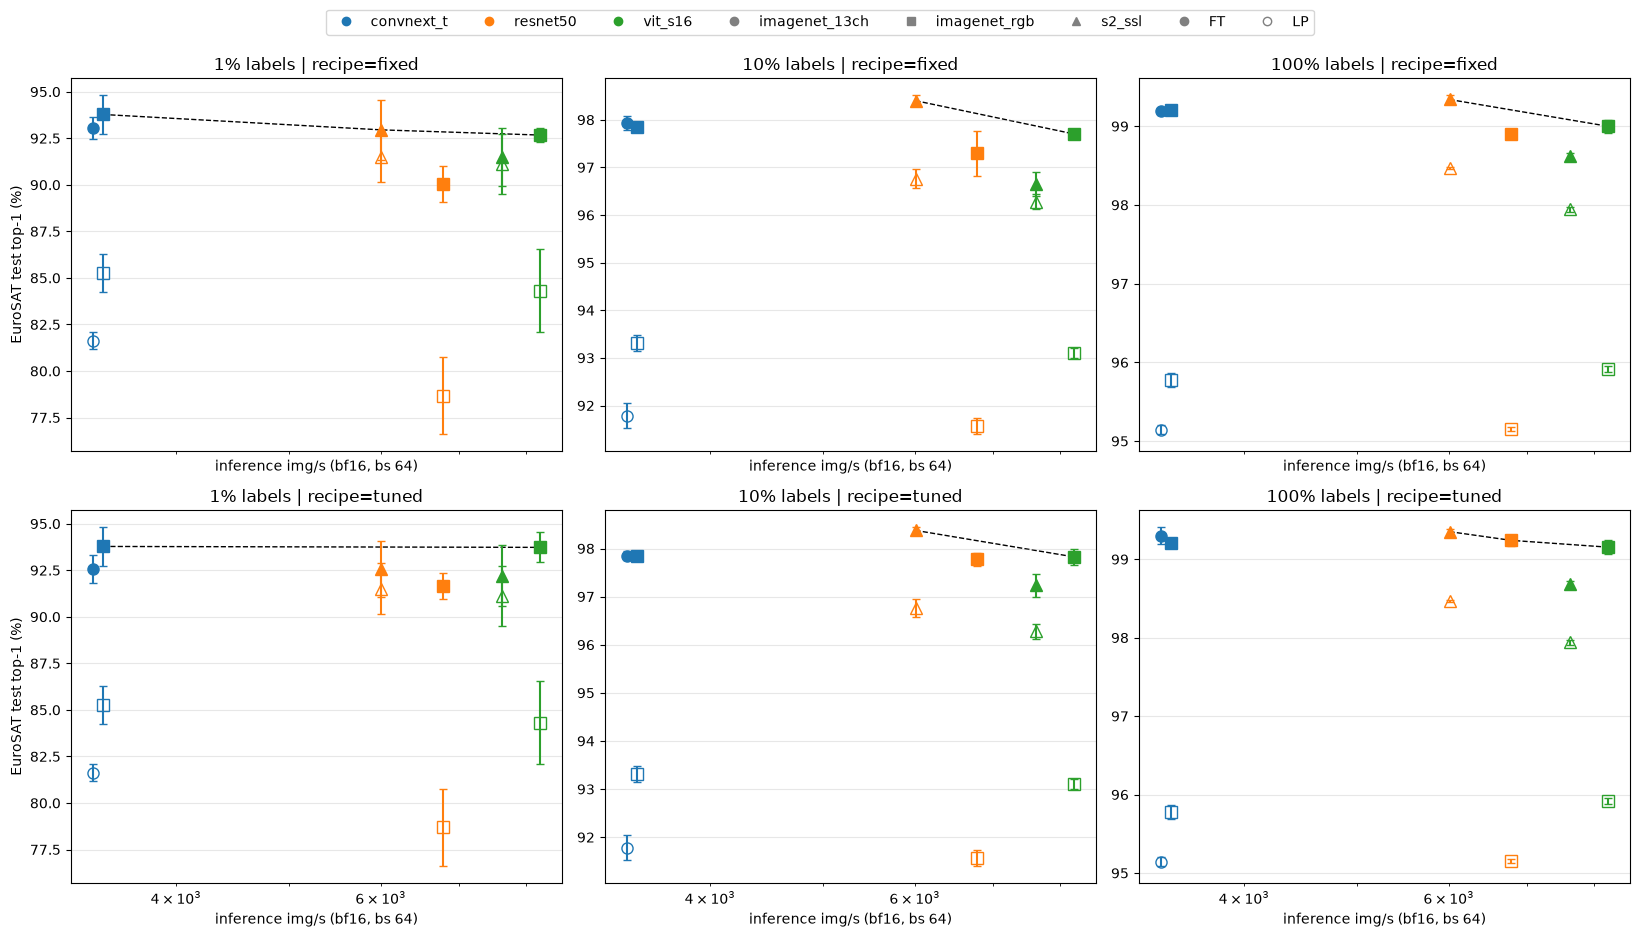

In [8]:
if bench is None:
    print("no bench.csv -> run the benchmark cell")
else:
    fig = an.plot_pareto(agg, SPLIT_BY, xlabel="inference img/s (bf16, bs 64)")
    fig.savefig(os.path.join(OUT_DIR, "pareto.png"), dpi=150, bbox_inches="tight")
    plt.show()


## Reading the results (fill in after running)
Things to check / expected patterns to confirm or refute:
- **Label efficiency:** S2-SSL init should help most at 1% and in **LP** (in-domain features, all 13 bands); gap shrinks at 100% FT.
- **LP vs FT:** ImageNet-RGB features usually have a large FT−LP gap on EuroSAT; SSL4EO features a smaller one.
- **Bands vs pretraining:** if `imagenet_13ch` is enabled, `imagenet_13ch − imagenet_rgb` isolates the value of extra bands; `s2_ssl − imagenet_13ch` isolates in-domain pretraining.
- **Speed:** at 224² ResNet-50 and ConvNeXt-T are typically close; ViT-S/16 (196 tokens) is often the fastest in bf16 on recent GPUs. Stem `in_chans` 3→13 should barely move img/s.
- **Pareto:** state which configs sit on the frontier per label regime, and the recommendation for a deployment that needs X img/s.

## Models + per-init input spec (`bakeoff/models.py`)
`build(bb, init, num_classes)` → `(model, spec)`. `spec` = bands, scale, clip, mean, std used by `prep` on GPU.
S2-SSL weights loaded into a plain timm model (same as `torchgeo.models.resnet50(weights=...)` does internally), with a check that only head/final-norm keys are missing.

### `imagenet_13ch`: stretching an RGB stem to 13 bands
`timm.create_model(..., pretrained=True, in_chans=13)` loads all ImageNet weights unchanged except the first conv (ConvNeXt `stem.0`: 4×4 stride-4, weight `[96, 3, 4, 4]` → `[96, 13, 4, 4]`), adapted by `timm.models.adapt_input_conv`:
```python
w = w.repeat(1, ceil(13 / 3), 1, 1)[:, :13]  # tile R,G,B filter slices cyclically
w *= 3 / 13                                   # keep output magnitude
```
Band *i* (SSL order) gets the filter slice of RGB channel *i mod 3*:

| band | B01 | B02 | B03 | B04 | B05 | B06 | B07 | B08 | B8A | B09 | B10 | B11 | B12 |
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
| filter | R | G | B | R | G | B | R | G | B | R | G | B | R |

- Why 3/13: a stem output is Σ over input channels. With inputs of similar stats (per-band z-score), 13 terms instead of 3 would blow up activations ~13/3×; the rescale keeps the first feature map at ImageNet scale so the pretrained norms/blocks downstream still see familiar statistics.
- Effect: at step 0 each output ≈ the RGB filter response averaged over "pseudo-R/G/B" band groups — not the true RGB image (B02/B03 get G/B, not B/G). Positional, not spectral, mapping. FT learns to re-weight bands; LP is stuck with this mix.
- Rest of the network (stages, norms) = ImageNet-22k weights; head = new random 10-class layer.